# 이론 뒤 확인 실습 S0~S3

이 노트북은 계산과 실행을 확인하는 실습편입니다. 처음이라면 [전체 흐름](https://github.com/tsi03048/resnet20-accel/blob/main/docs/learning/theory_first.md)을 읽고, [학습 목차](https://github.com/tsi03048/resnet20-accel/blob/main/docs/basic_track.md)의 기본 이론을 먼저 읽습니다.


저장된 출력은 기본 경로를 점검한 실행 예시입니다. 본인 결과는 준비 셀부터 다시 실행해 확인합니다. 전체 데이터 평가와 실제 보드 실행은 이 예시에 포함하지 않았습니다.

## 실행 전에 짚어 볼 것

필터는 같은 위치끼리 곱해 더하고, 학습은 벌점이 줄어드는 쪽으로 값을 고칩니다. 잔차 연결은 원래 입력을 마지막 더하기까지 보관합니다. 정수를 더할 때는 눈금을 맞춥니다.

낯선 내용이 있다면 [B1 필터](https://github.com/tsi03048/resnet20-accel/blob/main/docs/fundamentals/B1.md), [A4 학습](https://github.com/tsi03048/resnet20-accel/blob/main/docs/fundamentals/A4.md), [B4 잔차 연결](https://github.com/tsi03048/resnet20-accel/blob/main/docs/fundamentals/B4.md), [A6 눈금](https://github.com/tsi03048/resnet20-accel/blob/main/docs/fundamentals/A6.md)에서 해당 설명을 읽고 돌아옵니다. 준비됐다면 아래 셀을 순서대로 실행합니다.


## 준비 셀부터 순서대로 실행합니다

각 실습은 예상 → 실행 → 결과 읽기 → 값 하나 바꾸기 순서입니다. 셀 실행이 끝난 뒤 다음 셀로 갑니다. 오류가 나면 아래 셀을 더 실행하기 전에 해당 단계의 확인 표를 봅니다. 준비 셀은 프로젝트 폴더와 버전을 보여 줍니다.

In [1]:
# 0. 저장소 준비. 다시 실행해도 폴더 안에 중첩 복제하지 않는다.
import os, sys, subprocess
from pathlib import Path
repo = Path('/content/resnet20-accel') if Path('/content').is_dir() else (Path.cwd() if (Path.cwd() / 'model/common.py').exists() else Path.cwd() / 'resnet20-accel')
if not (repo / 'model/common.py').exists():
    subprocess.run(['git', 'clone', 'https://github.com/tsi03048/resnet20-accel.git', str(repo)], check=True)
os.chdir(repo)
sys.path.insert(0, str(repo))
print('실행 폴더:', repo)
if (repo / '.git').exists():
    version = subprocess.run(['git', 'rev-parse', 'HEAD'], check=True, capture_output=True, text=True).stdout.strip()
else:
    version = 'ZIP/local copy: 사용한 배포 ZIP 이름을 기록하세요.'
print('소스 버전:', version)


# 실행 결과는 아래에서 필요한 항목만 읽습니다. 오류가 나면 원문을 보여 줍니다.
def run_module(module, *args):
    completed = subprocess.run([sys.executable, '-m', module, *args],
                               capture_output=True, text=True, encoding='utf-8')
    if completed.returncode:
        print(completed.stdout)
        print(completed.stderr)
        completed.check_returncode()

import json
def read_step(name):
    return json.loads(Path(f'results/learning/{name}.json').read_text(encoding='utf-8'))['lessons'][name]


실행 폴더: [프로젝트 복사본: 로컬 경로 생략]
소스 버전: ZIP/local copy: 사용한 배포 ZIP 이름을 기록하세요.


## S0 먼저 예측하기

4×4 입력에 3×3 필터를 적용하면 왜 출력이 네 개일까요? 첫째 줄 첫째 칸인 X[0][0]만 5→6으로 바꾸면 어느 출력이 변할까요?

In [2]:
run_module('exercises.conv_walkthrough')
run_module('exercises.step_up', 'conv')
conv = read_step('conv')
print('입력 변경 전:', conv['before'])
print('X[0][0]을 1 늘린 뒤:', conv['after_X00_plus_1'])
print('첫 출력의 중간 합:', conv['first_psum'])
print('기록: results/basic/conv_trace.csv / results/learning/conv.json')

입력 변경 전: [10, 9, 8, 6]
X[0][0]을 1 늘린 뒤: [11, 9, 8, 6]
첫 출력의 중간 합: [5, 5, 4, 8, 8, 7, 10, 10, 10]
기록: results/basic/conv_trace.csv / results/learning/conv.json


### S0 결과 읽기

Y=[10,9,8,6]은 위 왼쪽부터 줄 순서의 네 출력입니다. before는 입력 변경 전, after_X00_plus_1=[11,9,8,6]은 첫 입력만 1 늘린 뒤입니다. CSV의 x·w → product → psum 순서로 처음 다른 행을 찾습니다. [S0 오류별 확인 표](https://github.com/tsi03048/resnet20-accel/blob/main/docs/learning/S0.md)

기록: 결과 네 개와 첫 출력만 달라지는 이유 한 문장.

## S1 환경 준비

Colab은 브라우저에서 파이썬을 실행하는 환경이고, PyTorch는 모델 계산 도구입니다. 다음 단계는 한 장만 실행합니다.

In [3]:
import importlib.util
for package in ('numpy', 'PIL', 'torch', 'torchvision'):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'], check=True)

## 이미지 한 장 예측

입력 [1,3,32,32]는 RGB 이미지 한 장입니다. 출력 [1,10]은 고양이·자동차 같은 후보 종류별 점수입니다. 정답을 보지 않고 가장 큰 점수만 골라 보세요.

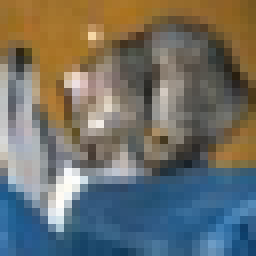

정답: cat | 예측: cat | logits: [1, 10]


In [4]:
subprocess.run([sys.executable, '-m', 'model.first_prediction', '--device', 'auto'], check=True)
import json
from IPython.display import display, Image, SVG
pred = json.loads(Path('results/learning/first_prediction/prediction.json').read_text(encoding='utf-8'))
display(Image(filename='results/learning/first_prediction/image.png'))
print('정답:', pred['label'], '| 예측:', pred['prediction'], '| logits:', pred['logits_shape'])

### 점수 그림을 읽기 전에

먼저 사진을 보고, 다음 그림에서 가장 큰 점수의 이름을 찾습니다. 오른쪽은 양수, 왼쪽은 음수입니다. 막대 길이의 절댓값이 아니라 숫자가 가장 큰 후보를 고릅니다. 색이 다른 막대는 모델이 고른 후보입니다. 그 이름을 확인한 뒤 정답과 비교하세요.

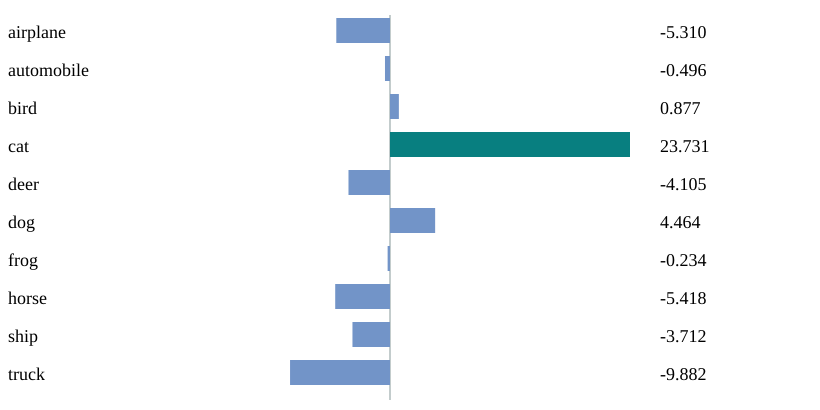

In [5]:
# Logit 0을 기준으로 양수·음수 점수를 같은 눈금에 표시합니다.
scores = pred['logits']
scale = 240 / max(max(abs(v) for v in scores), 1e-9)
parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="410"><rect width="100%" height="100%" fill="white"/><line x1="390" x2="390" y1="15" y2="400" stroke="#899"/>']
for i, (name, v) in enumerate(zip(pred['classes'], scores)):
    y = 18 + i*38
    x = 390 + min(v, 0)*scale
    width = abs(v)*scale
    color = '#087f80' if i == pred['prediction_index'] else '#7294c8'
    parts.append(f'<text x="8" y="{y+20}" font-size="18">{name}</text><rect x="{x}" y="{y}" width="{width}" height="25" fill="{color}"/><text x="660" y="{y+20}" font-size="18">{v:.3f}</text>')
parts.append('</svg>')
display(SVG(''.join(parts)))

### S1 확인하고 넘어가기

prediction_index=3, prediction=cat이면 이번 기준 사진의 예측을 재현했습니다. label은 비교할 정답입니다. 음수 점수는 오류가 아니며 한 장 성공은 전체 정확도가 아닙니다. 예측이 다르면 classes와 logits의 같은 위치를 읽었는지, sample_index가 0인지 먼저 봅니다. [S1 오류별 확인 표](https://github.com/tsi03048/resnet20-accel/blob/main/docs/learning/S1.md)

## 값을 바꿔 예측하기

점수를 복사해 다른 클래스의 값을 최댓값보다 1 크게 만들면 무엇이 선택될까요? 이것은 가장 큰 점수의 위치를 고르는 Argmax 규칙 실험이며 모델 학습 결과가 아닙니다.

In [6]:
changed_scores = scores.copy()
other = (pred['prediction_index'] + 1) % 10
changed_scores[other] = max(scores) + 1
print('선택:', pred['classes'][max(range(10), key=lambda i: changed_scores[i])])

선택: deer


## S2 짧은 학습과 Residual 실험

먼저 w=0.5, Gradient=-2, 학습률=0.1의 새 Weight를 계산하세요. 이어 Conv2 뒤에 ReLU를 추가하면 어떤 값이 사라지는지 예측합니다.

In [7]:
for lesson in ('learn', 'residual'):
    run_module('exercises.step_up', lesson)
learn = read_step('learn')
print('학습 전:', learn['before'])
print('기울기:', learn['gradient'])
print('수정 후:', learn['after'])
residual = read_step('residual')
for key in ('X', 'H', 'main', 'Y', 'wrong_extra_ReLU'):
    print(key, ':', residual[key])

학습 전: {'w': 0.5, 'b': 0.5, 'prediction': 1.5, 'loss': 0.25}
기울기: {'w': -2.0, 'b': -1.0}
수정 후: {'w': 0.7, 'b': 0.6, 'prediction': 2.0, 'loss': 0.0}
X : [1, 2, 3, 4]
H : [0, 1, 3, 5]
main : [0.5, -0.5, -2.5, -4.5]
Y : [1.5, 1.5, 0.5, 0]
wrong_extra_ReLU : [1.5, 2, 3, 4]


### S2 결과 읽기

learn의 before → gradient → after를 읽습니다. w=0.7과 b=0.6을 함께 써야 새 예측이 2입니다. residual은 별개 실험입니다. X → H → main → Y 순서로 보며 main은 본문의 M입니다. H=[0,1,3,5], main=[0.5,-0.5,-2.5,-4.5], Y=[1.5,1.5,0.5,0]입니다. wrong_extra_ReLU가 Y와 다른 것은 의도한 비교입니다.

둘째 원소 X=2 하나를 따라가세요. H=1 → main=-0.5 → Y=1.5입니다. 다르면 처음 다른 단계부터 봅니다. [S2 확인 표](https://github.com/tsi03048/resnet20-accel/blob/main/docs/learning/S2.md)

## S3 정수 단위 실험

저장한 정수(code) 8·눈금(Scale) 1/8과 정수 4·눈금 1/4를 더해 출력 Scale 1/8로 표현하면 얼마일까요?

In [8]:
run_module('exercises.step_up', 'quant')
quant = read_step('quant')
print('눈금을 맞춘 합 correct_code:', quant['correct_code'])
print('눈금을 무시한 비교값 wrong_raw_sum:', quant['wrong_raw_sum'])
print('반올림 nearest_even:', quant['nearest_even'])

눈금을 맞춘 합 correct_code: 16
눈금을 무시한 비교값 wrong_raw_sum: 12
반올림 nearest_even: {'2.5': 2, '3.5': 4, '-2.5': -2, '-3.5': -4}


### S3 결과 읽기

correct_code=16은 눈금을 맞춘 결과, wrong_raw_sum=12는 눈금을 무시한 비교값입니다. 2가 나왔다면 실제 합을 구한 것이므로 출력 눈금 1/8로 다시 나눕니다. nearest_even의 -2.5→-2, -3.5→-4도 확인하세요. [S3 확인 표](https://github.com/tsi03048/resnet20-accel/blob/main/docs/learning/S3.md)

여기까지가 기본 실행입니다. 다음 두 전체 평가 셀은 기본값 False로 두면 건너뜁니다.

## 선택: 소수 계산(FP32)으로 전체 평가

한 장의 정답을 전체 정확도로 기록하지 않습니다. 아래 True를 선택하면 Test 10,000장을 내려받아 평가하므로 추가 시간이 듭니다.

In [9]:
RUN_FULL_FP32 = False
if RUN_FULL_FP32:
    if importlib.util.find_spec('datasets') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'datasets'], check=True)
    subprocess.run([sys.executable, '-m', 'model.run_reference', '--device', 'auto', '--e1-only'], check=True)
else:
    print('이번 실행은 한 장 예측입니다. 저장소 기존 전체 평가 JSON은 본인 실행 결과가 아닙니다.')

이번 실행은 한 장 예측입니다. 저장소 기존 전체 평가 JSON은 본인 실행 결과가 아닙니다.


## 선택: 학습 후 정수화(PTQ)의 눈금 후보 비교

학습 사진 중 눈금 결정용 1,000장과 겹치지 않는 설정 비교용 1,000장으로 설정을 고른 뒤, 따로 남긴 시험 사진(Test)으로 한 설정만 평가합니다. Bias는 FP32입니다. 실제 정수 기준 E2-B는 별도 구현·검증 완료 상태이며, 다음 노트북에서 한 장을 재현합니다. 허용 하락 폭은 팀이 정하고 None이면 자동 승인하지 않습니다.

In [10]:
RUN_PTQ = False
ACCEPT_DROP_PP = None
if RUN_PTQ:
    if importlib.util.find_spec('datasets') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'datasets'], check=True)
    command = [sys.executable, '-m', 'model.run_reference', '--device', 'auto']
    if ACCEPT_DROP_PP is not None:
        command += ['--accept-drop-pp', str(ACCEPT_DROP_PP)]
    subprocess.run(command, check=True)
else:
    print('PTQ는 실행하지 않았습니다.')

PTQ는 실행하지 않았습니다.


## 본인 결과 저장

배포된 기존 전체 평가 결과와 섞이지 않도록 첫 예측·짧은 실습 폴더만 저장합니다. 전체 평가를 실행했다면 results/run_manifest.json과 해당 결과도 별도로 보관하세요.
[E2-B 정수 한 장](https://colab.research.google.com/github/tsi03048/resnet20-accel/blob/main/notebooks/E2B_integer_reference.ipynb)

In [11]:
from zipfile import ZipFile, ZIP_DEFLATED
with ZipFile('learning_outputs.zip', 'w', ZIP_DEFLATED) as z:
    for item in ('results/basic/conv_result.json', 'results/basic/conv_trace.csv',
                 'results/learning/conv.json', 'results/learning/learn.json',
                 'results/learning/residual.json', 'results/learning/quant.json',
                 'results/learning/first_prediction/image.png',
                 'results/learning/first_prediction/prediction.json'):
        p = Path(item)
        if p.is_file(): z.write(p)
try:
    from google.colab import files
    files.download('learning_outputs.zip')
except ImportError:
    print(Path('learning_outputs.zip').resolve())

[프로젝트 복사본: 로컬 경로 생략]\learning_outputs.zip
